# PHGarfield configurations judged with tracks: run 79513 (2026-10-23)

**Jobs**: `Fun4All_TPC_reco_garfield.C` (production TPC reconstruction, PHGarfield configured in the macro, shared by the crossing
finder and the clusterizer; tag `default` = no macro instance, as production), 77 configurations × 10 segments (0 … 2160) × 1000
events. Configurations from `make_trk_configs.py`: the final CM calibration of 79513 (f9_s795) and variations of keff, module
gains (v13), map shapes and R1 weight (v14), field cage, frames, magnet placement, B scale, ωτ, B_φ, P/T.

**Track selection (always)**: ntpc_clusters > 30, pT > 0.2 GeV, |η| < 1.1, |rDCA_zero| < 3 cm, fitted (fit_status 1); every study
per side (track side: South / North) and charge.

**Observables**
* rDCA_zero (= |circle centre| − radius) vs track φ (φ = atan2(py, px)), core mean in ±4 mm windows, per charge;
  **charge-odd** (q+ − q−)/2 = spatial / pointing shift, **charge-even** (q+ + q−)/2 = curvature / momentum (see Section 2);
* **pT-spectrum slope ratio** s(q+)/s(q−) (ln N = a + s pT, 0.3 < pT < 2.5 GeV) vs φ and vs η: a momentum-scale difference between
  the charges moves the ratio away from 1;
* **fit residual**: r·Δφ of every cluster to a circle fitted in xy to the track's own clusters, at the cluster radius (core mean
  ±1 mm), vs R per charge, its charge-odd and charge-even parts, and per (φ, R).

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '/home/yoren/bnl/ROOT/install/lib')
import numpy as np, matplotlib.pyplot as plt
from IPython.display import display
import trkana as ta
plt.rcParams['figure.dpi'] = 55
def show(*figs):
    for f in figs:
        display(f)
    plt.close('all')

## 1. All configurations: summary per side (identical numbers on one side = a knob of the other side)

In [2]:
rows = ta.table()

South: rDCA charge-odd (q+ - q-)/2 mean and first-harmonic amplitude, charge-even amplitude [mm]; pT-slope ratio s+/s-: mean, rms vs phi, rms vs eta; cluster rphi residual vs R: charge-odd and charge-even rms [um]
  config                       ntrk   odd<rDCA> [mm]          odd amp         even amp   slope ratio <>       rms vs phi       rms vs eta res odd rms [um]     res even rms
  default                    321329           -0.686            2.663            0.073            1.027            0.139            0.039            159.9            123.9
  default_shared             323366           -0.486            3.218            0.234            1.077            0.144            0.053            166.0            118.7
  final                      323384           -0.088            3.712            0.209            1.073            0.141            0.031            156.8             84.9
  final_k080                 323556           -2.515            3.120            0.106            

## 2. First reading
**Sign convention.** rDCA_zero = |track-circle centre| − radius: positive when the origin is outside the circle. A **spatial shift**
of a track (the same direction for both charges) puts the origin outside the circle for one bending direction and inside for the
other: it is **charge-odd** in this sign. A **curvature (momentum) error** moves the circle the same way relative to the origin for
both charges: it is **charge-even**. So below: charge-odd = pointing / position, charge-even = curvature / momentum.

* **Charge-odd (pointing)**: a first harmonic of ≈ ±4 mm vs φ, **the same in every pT bin** (0.2–5 GeV) – a position effect, not
  momentum. Without space-charge correction (static) it is flat at −4 mm; every space-charge correction (production default, final,
  shapes, keff) leaves the harmonic; its mean follows keff (≈ 12 mm per unit of keff scale; zero at ×1.01 South / ×0.97 North).
  The correction is centred on the TPC axis while the space charge is produced along the beam (≈ 2.7 mm off in y in 79513): a
  φ-dependent pointing error. Next: rDCA to the vertex (silicon) in addition to rDCA to (0, 0), and the space-charge centre / module
  gains fitted with tracks (gain-basis jobs).
* **Charge-even (curvature)**: sharp 1–2 mm dips at fixed φ spaced like the sector boundaries, in every pT bin, **identical in all
  configurations incl. the production default** – a module-edge effect PHGarfield does not touch.
* **Fit residuals** (r·Δφ to a circle fitted to the track's own clusters, at the cluster R): without space-charge correction a large
  R shape (+0.5 mm at 31 cm, −0.4 mm at 37 cm, up to −1.3 mm at 75 cm); the corrections remove most of it; what is left is a
  common structure (R1 / R2 and R2 / R3 boundaries, outer edge) the same for all corrections. The module's own `residual_rphi`
  projects the track to the cluster z (z-model errors leak in as a charge-odd ramp): not used.
* **pT-slope ratio and q+/q− yield ratio** vs φ: the same structure in all configurations (charge-dependent acceptance at the sector
  gaps); only the level follows keff.

## 3. Groups of configurations
For each group: rDCA vs φ (per charge, charge-odd, charge-even), slope ratio vs φ and η, residual vs R, and the charge-odd residual
map (φ, R).

### references

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/trkana.py:493: RuntimeWarning: divide by zero encountered in divide
  return a / b, ETAC


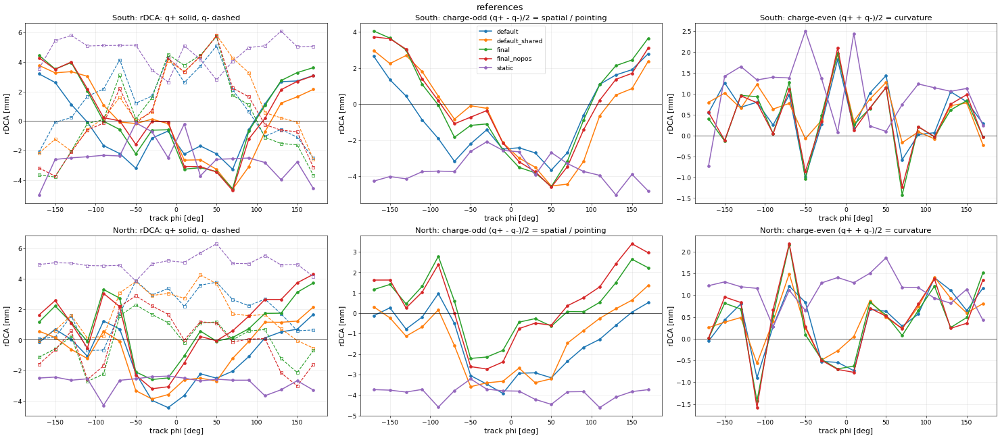

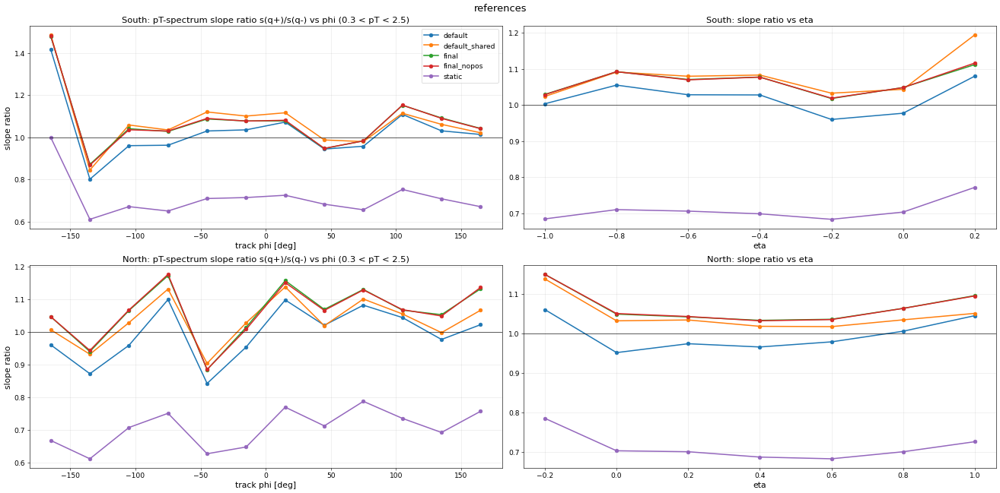

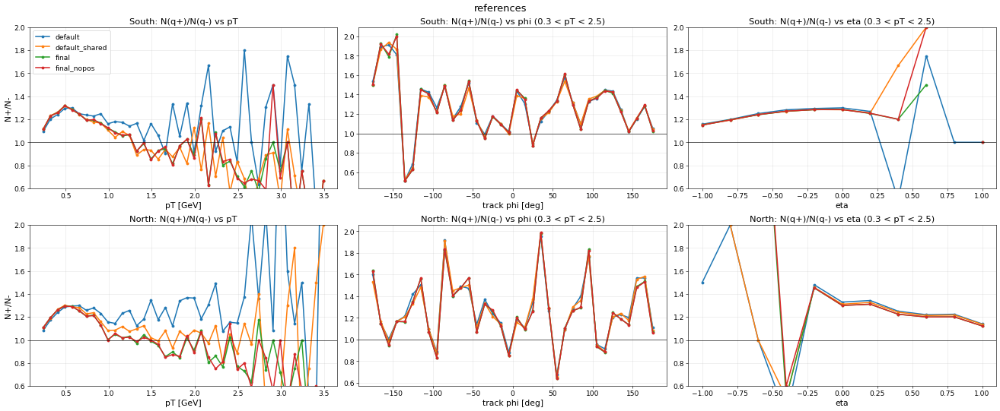

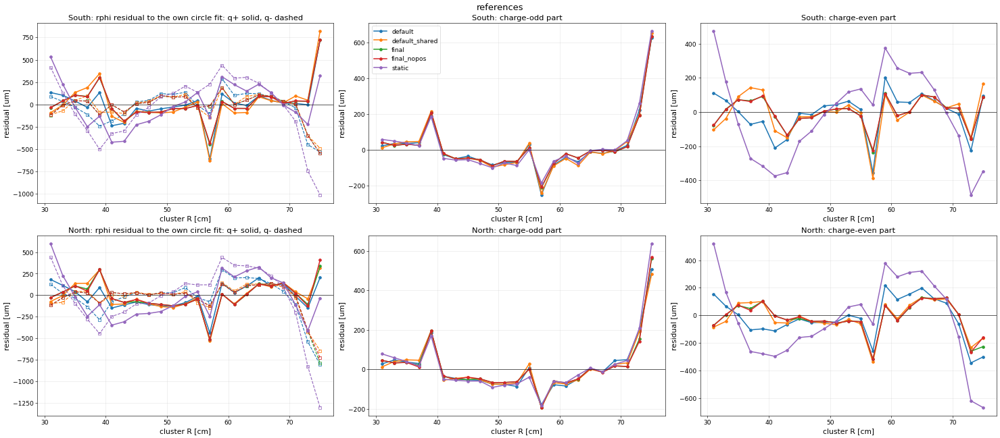

In [3]:
G = ta.GROUPS['references']
show(ta.fig_dca_big(G, 'references'), ta.fig_slope(G, 'references'), ta.fig_yield_ratio([t for t in G if t != 'static'], 'references'), ta.fig_resid(G, 'references'))

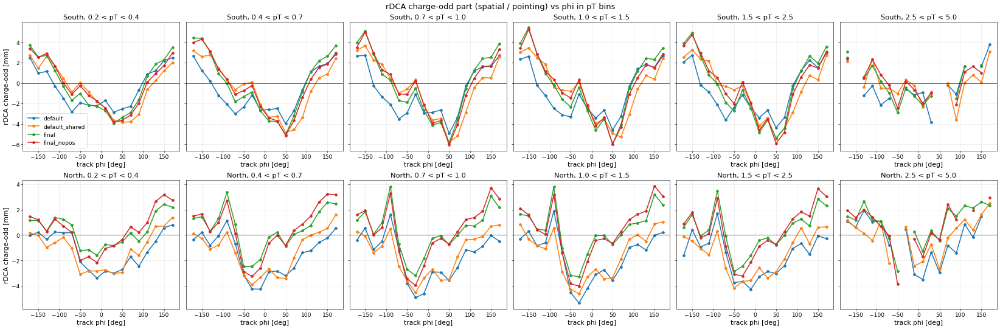

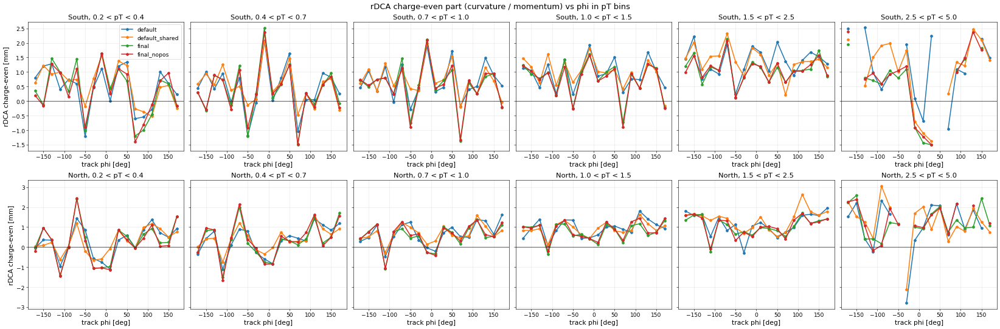

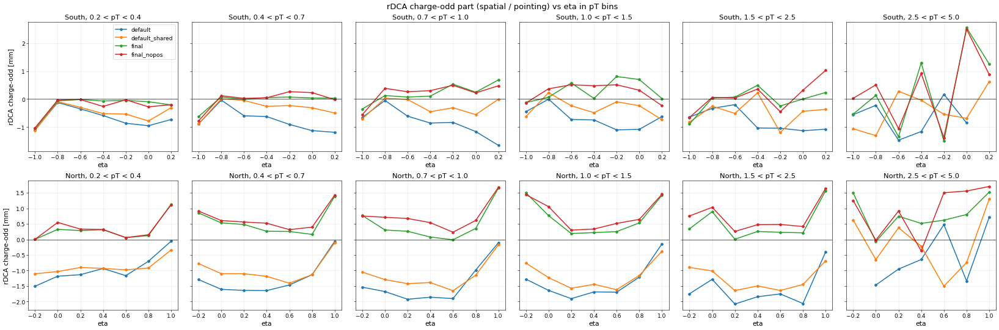

In [4]:
G = [t for t in ta.GROUPS['references'] if t != 'static']
show(ta.fig_dca_ptbins(G, 'odd', 'phi'), ta.fig_dca_ptbins(G, 'even', 'phi'), ta.fig_dca_ptbins(G, 'odd', 'eta'))

### keff

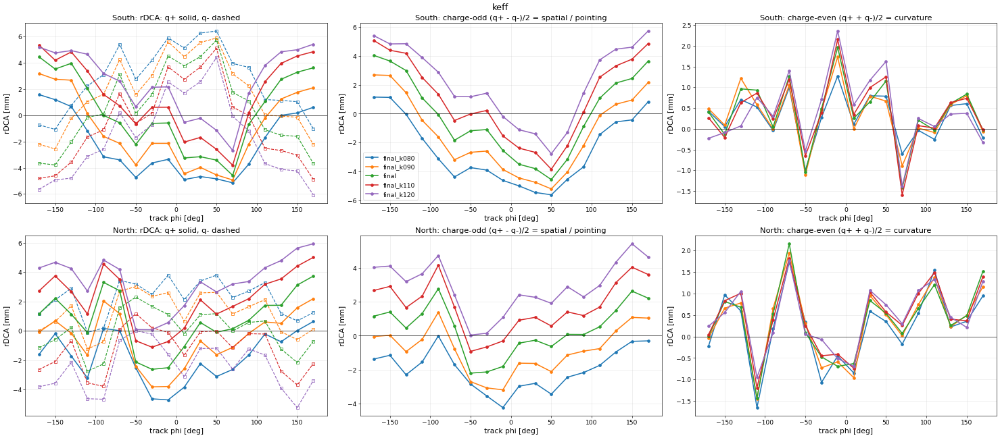

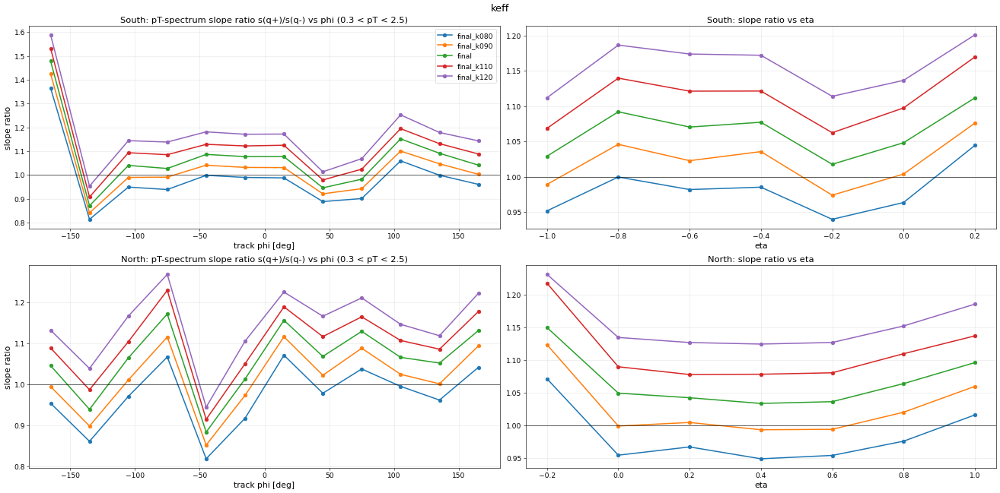

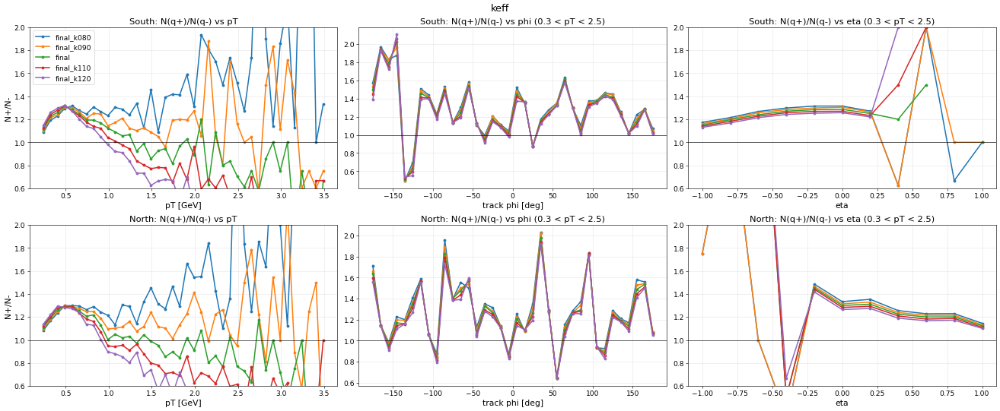

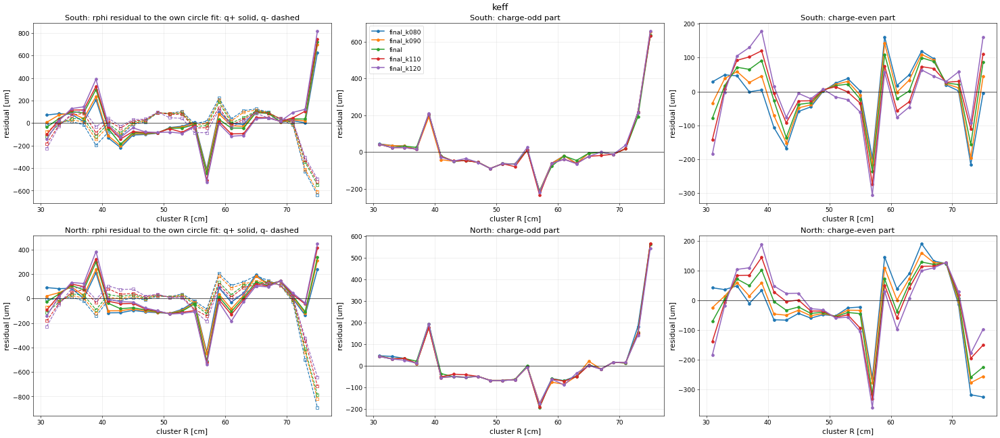

In [5]:
G = ta.GROUPS['keff']
show(ta.fig_dca_big(G, 'keff'), ta.fig_slope(G, 'keff'), ta.fig_yield_ratio([t for t in G if t != 'static'], 'keff'), ta.fig_resid(G, 'keff'))

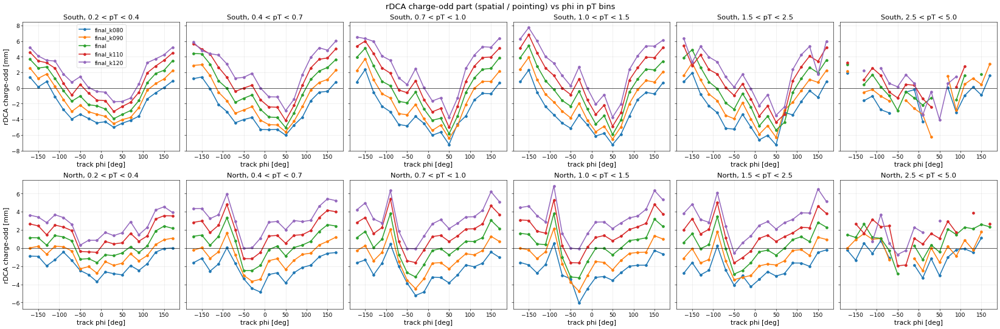

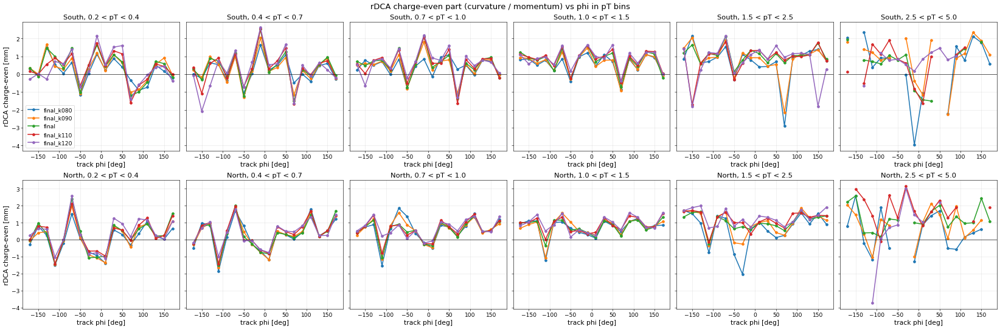

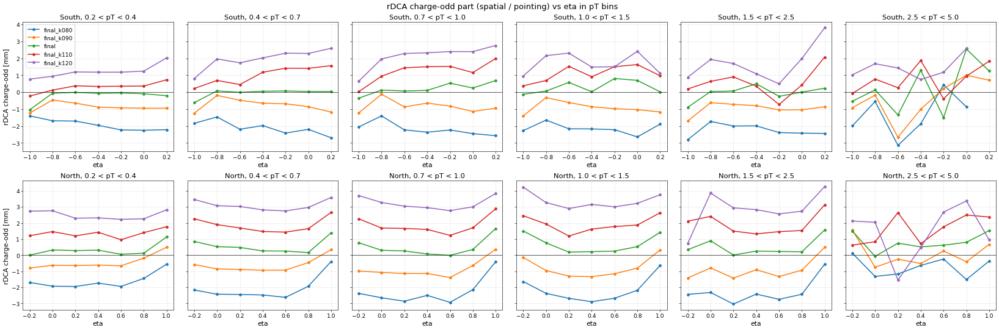

In [6]:
G = [t for t in ta.GROUPS['keff'] if t != 'static']
show(ta.fig_dca_ptbins(G, 'odd', 'phi'), ta.fig_dca_ptbins(G, 'even', 'phi'), ta.fig_dca_ptbins(G, 'odd', 'eta'))

### keff per side

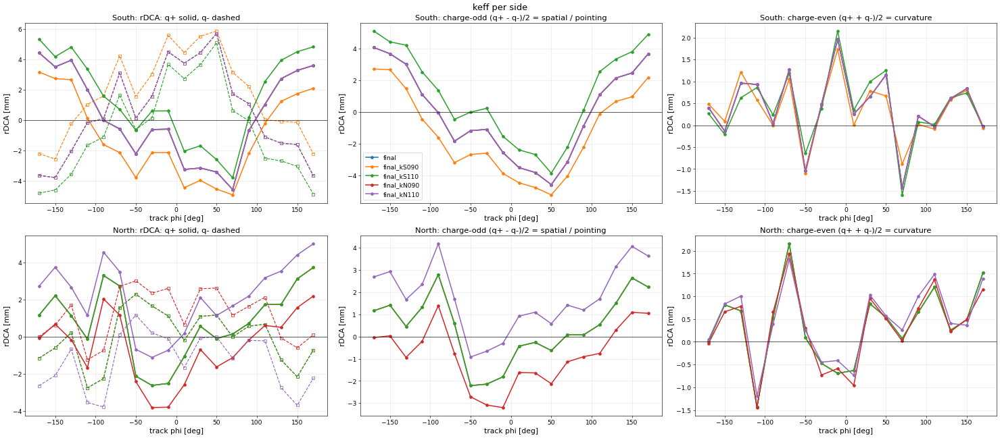

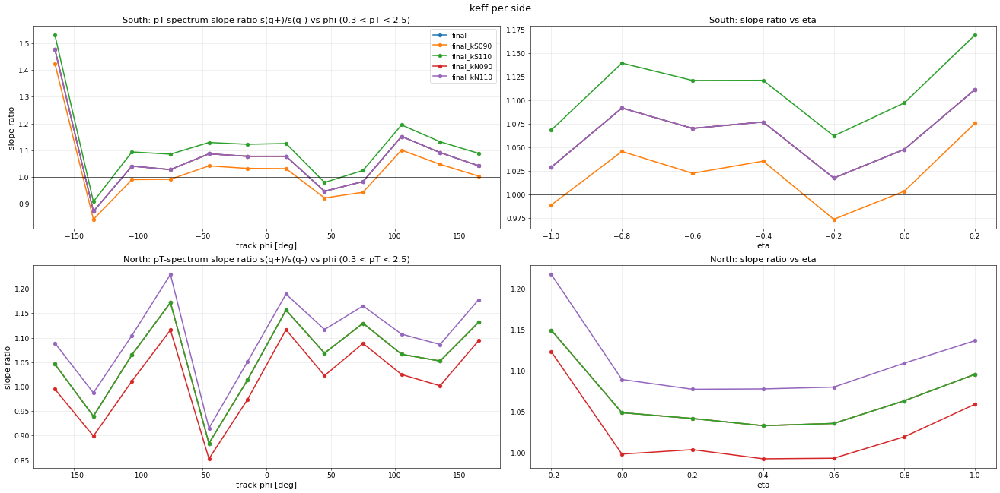

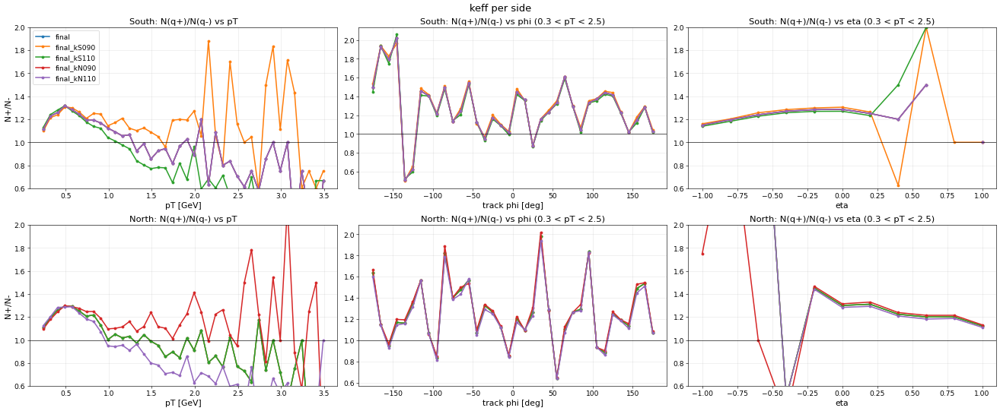

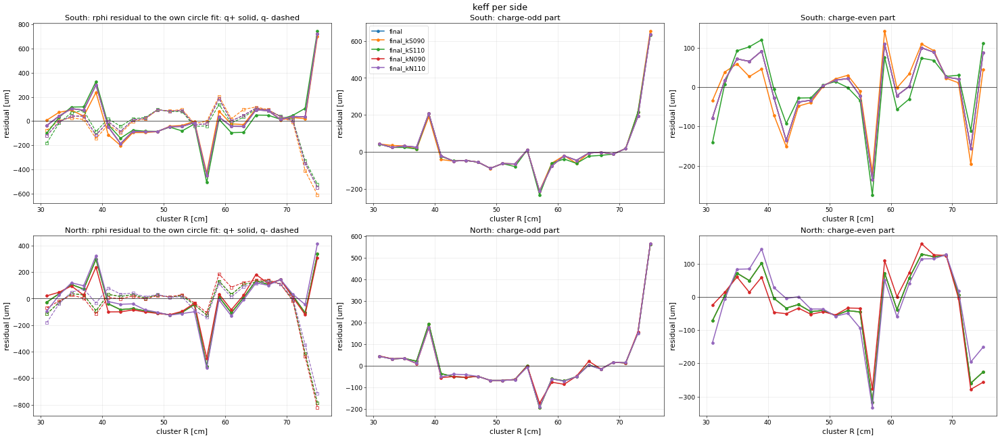

In [7]:
G = ta.GROUPS['keff per side']
show(ta.fig_dca_big(G, 'keff per side'), ta.fig_slope(G, 'keff per side'), ta.fig_yield_ratio([t for t in G if t != 'static'], 'keff per side'), ta.fig_resid(G, 'keff per side'))

### module gains (v13)

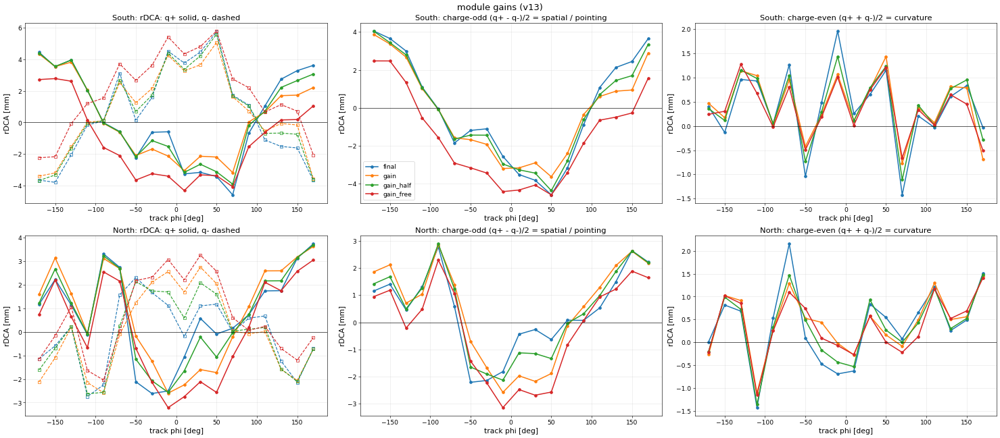

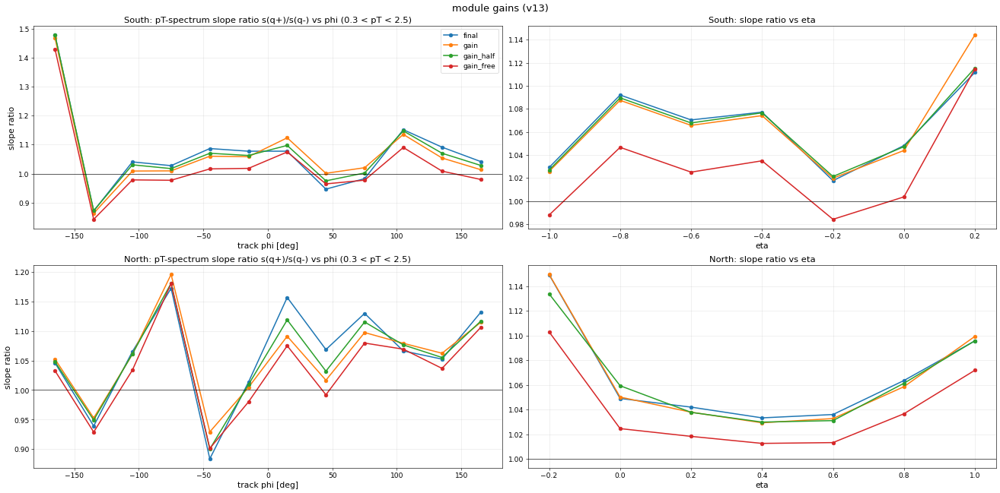

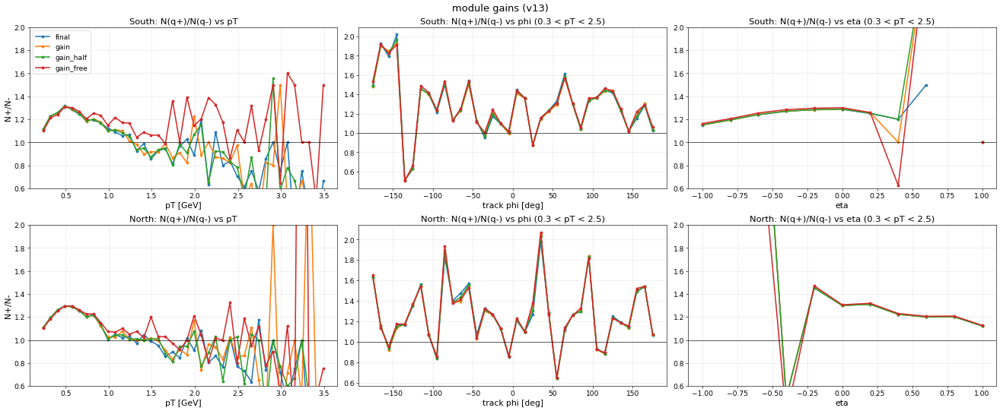

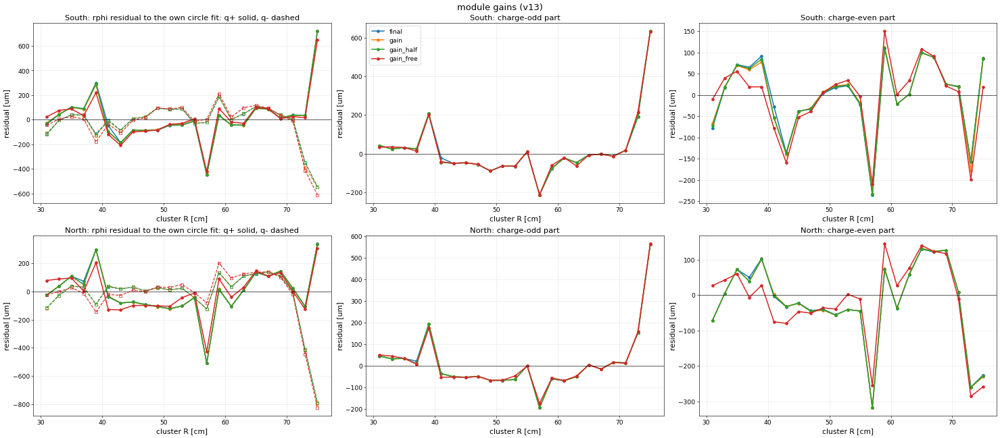

In [8]:
G = ta.GROUPS['module gains (v13)']
show(ta.fig_dca_big(G, 'module gains (v13)'), ta.fig_slope(G, 'module gains (v13)'), ta.fig_yield_ratio([t for t in G if t != 'static'], 'module gains (v13)'), ta.fig_resid(G, 'module gains (v13)'))

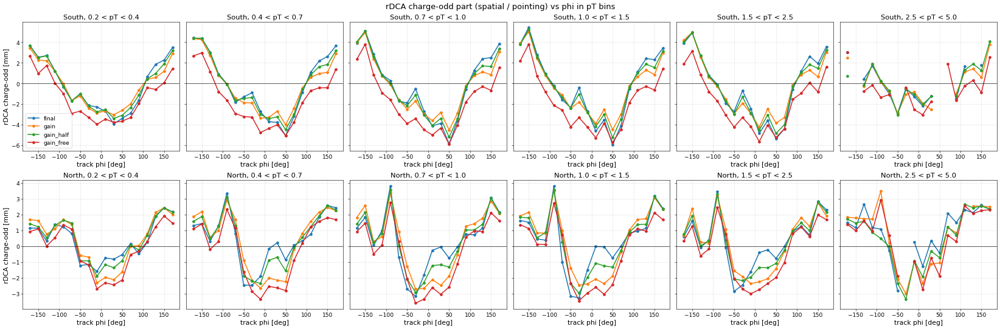

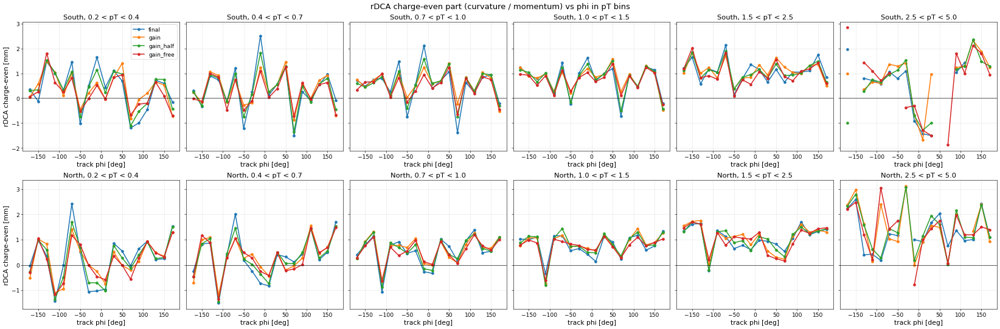

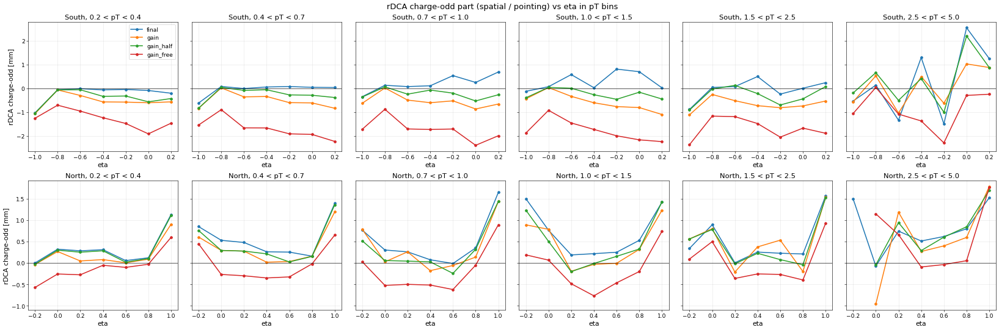

In [9]:
G = [t for t in ta.GROUPS['module gains (v13)'] if t != 'static']
show(ta.fig_dca_ptbins(G, 'odd', 'phi'), ta.fig_dca_ptbins(G, 'even', 'phi'), ta.fig_dca_ptbins(G, 'odd', 'eta'))

### map shapes (v14)

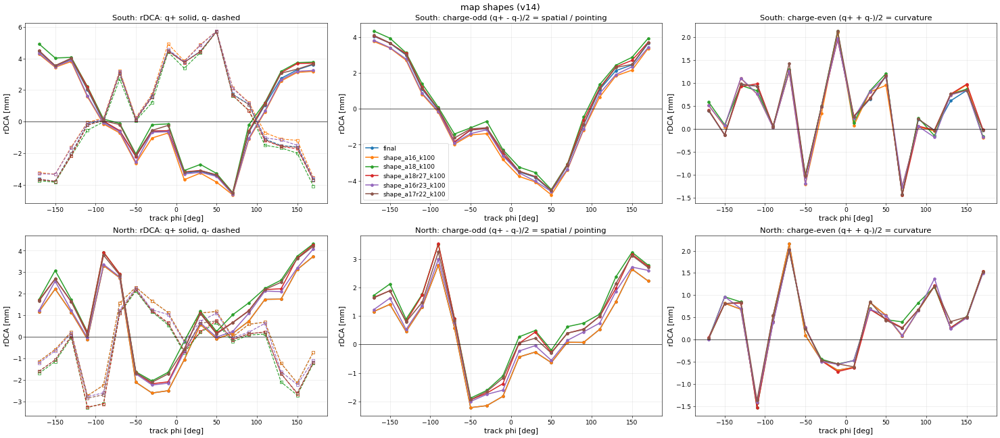

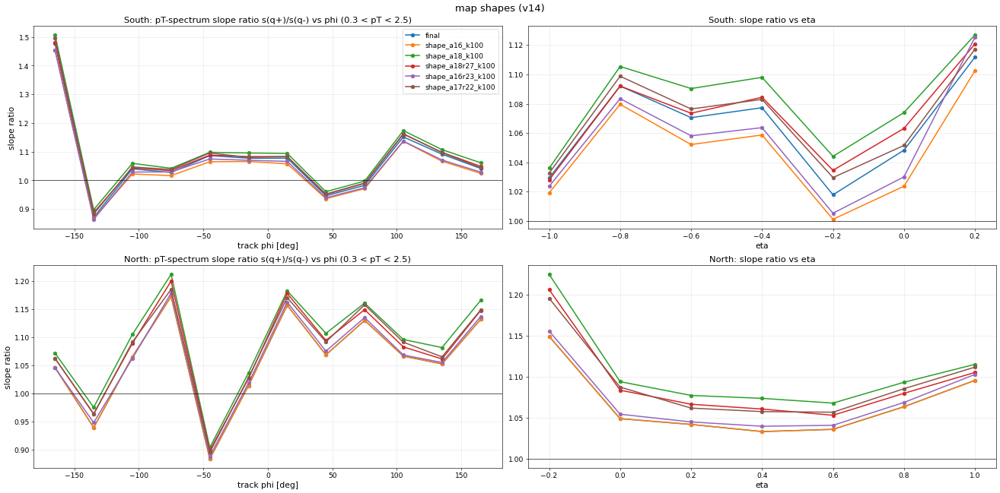

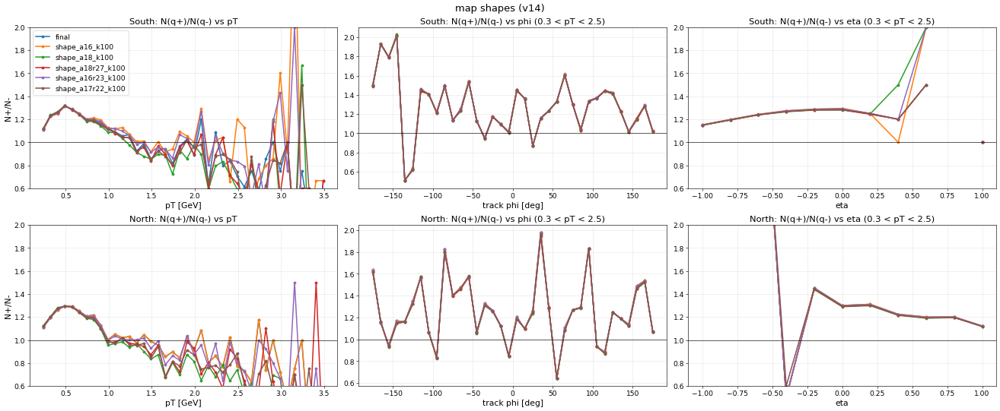

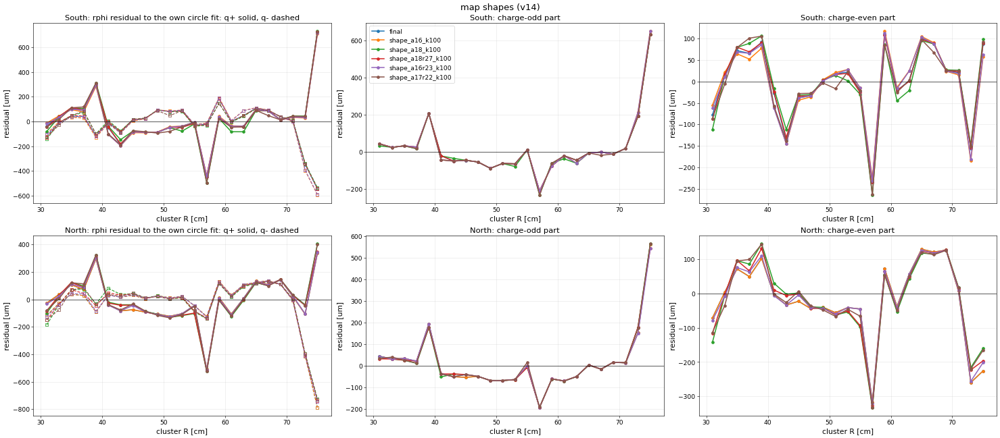

In [10]:
G = ta.GROUPS['map shapes (v14)']
show(ta.fig_dca_big(G, 'map shapes (v14)'), ta.fig_slope(G, 'map shapes (v14)'), ta.fig_yield_ratio([t for t in G if t != 'static'], 'map shapes (v14)'), ta.fig_resid(G, 'map shapes (v14)'))

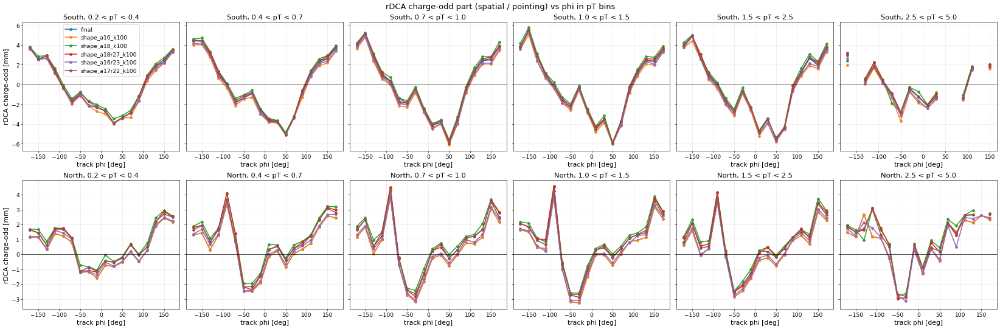

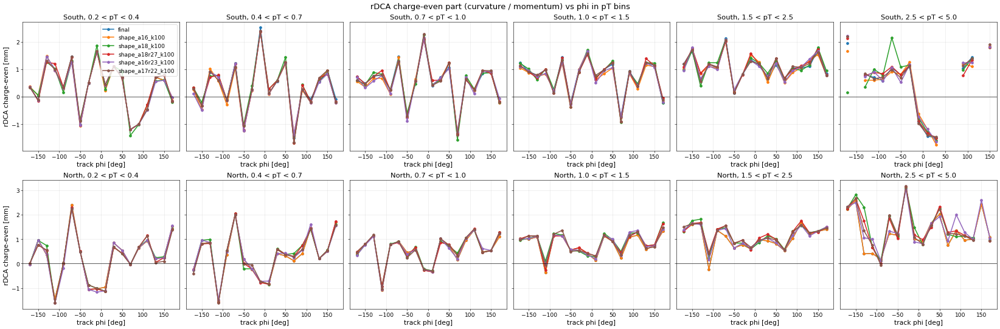

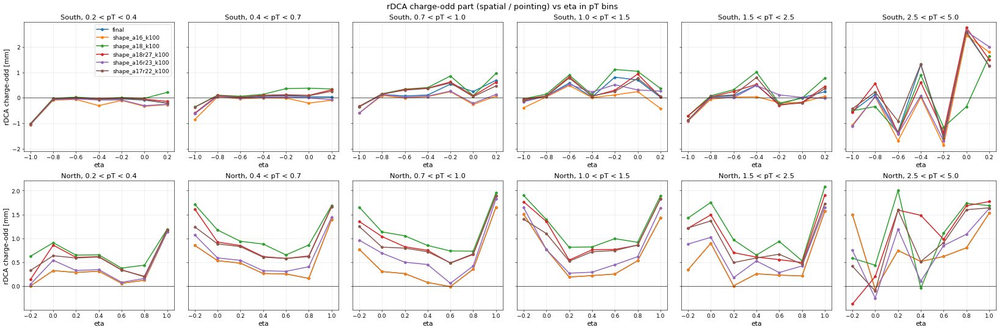

In [11]:
G = [t for t in ta.GROUPS['map shapes (v14)'] if t != 'static']
show(ta.fig_dca_ptbins(G, 'odd', 'phi'), ta.fig_dca_ptbins(G, 'even', 'phi'), ta.fig_dca_ptbins(G, 'odd', 'eta'))

### R1 weight (v14)

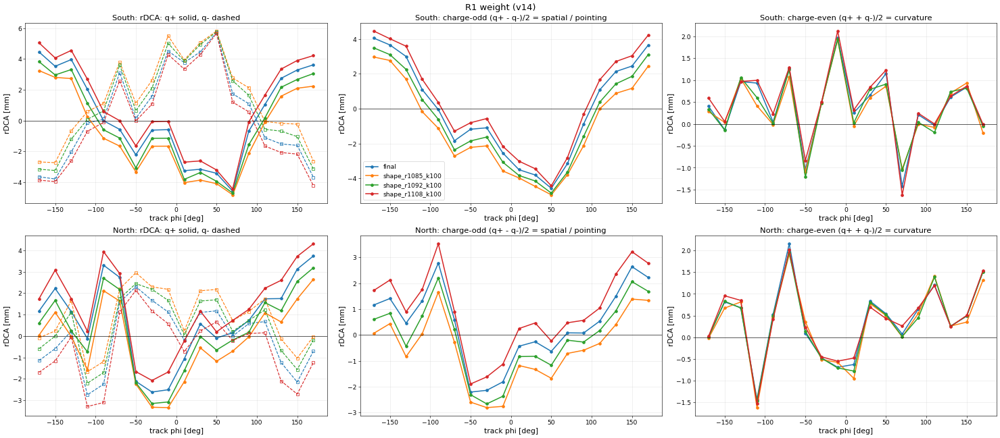

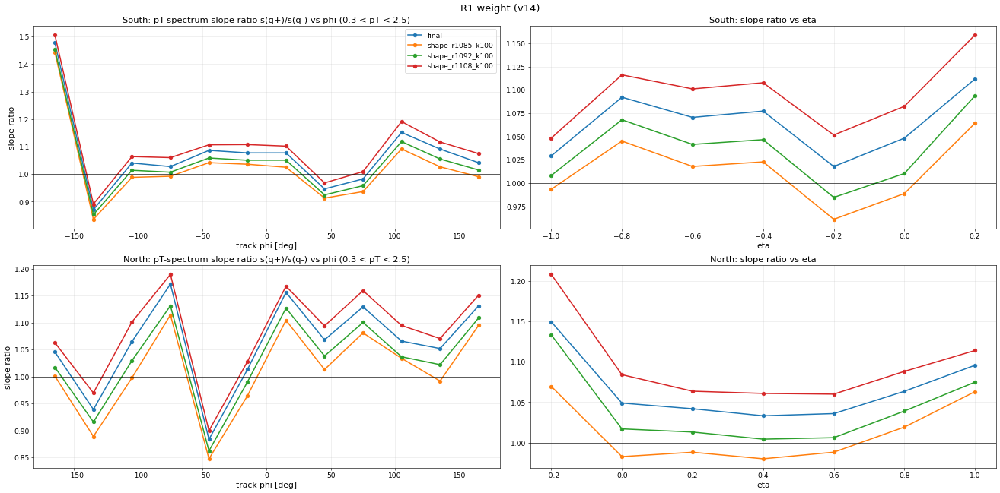

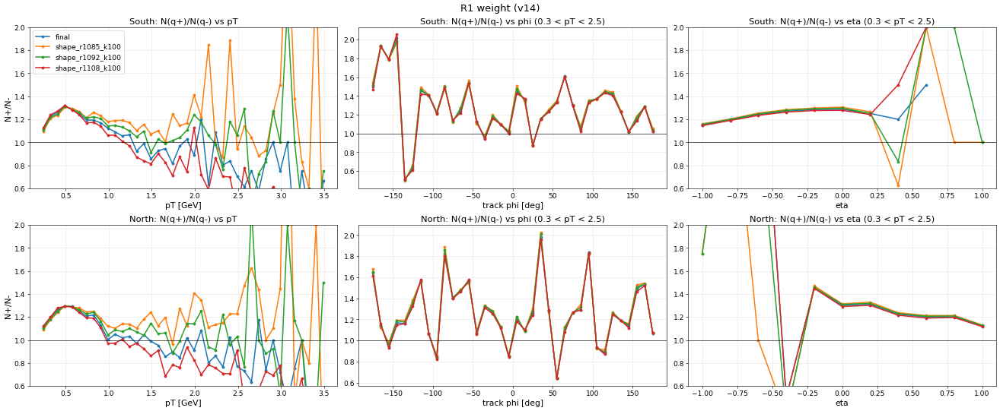

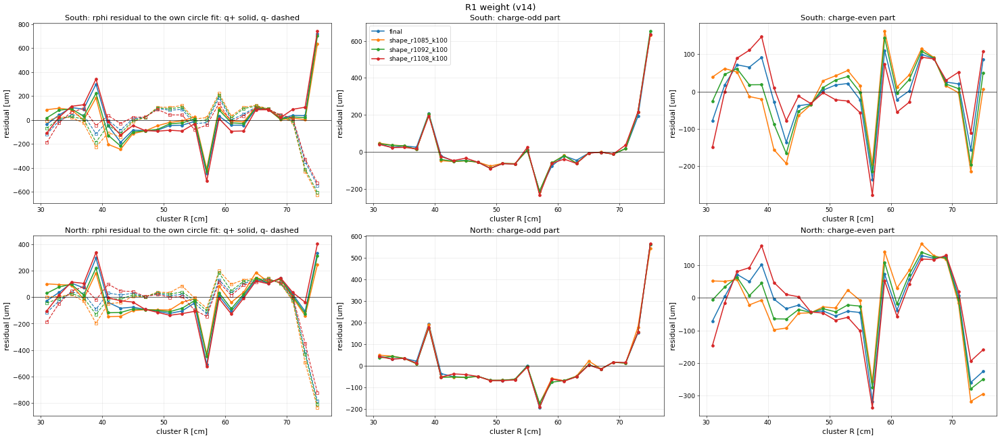

In [12]:
G = ta.GROUPS['R1 weight (v14)']
show(ta.fig_dca_big(G, 'R1 weight (v14)'), ta.fig_slope(G, 'R1 weight (v14)'), ta.fig_yield_ratio([t for t in G if t != 'static'], 'R1 weight (v14)'), ta.fig_resid(G, 'R1 weight (v14)'))

### IFC South

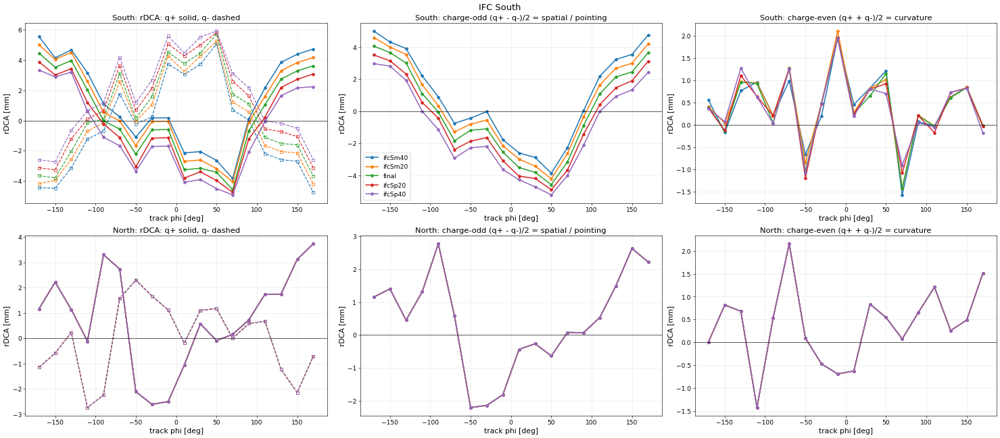

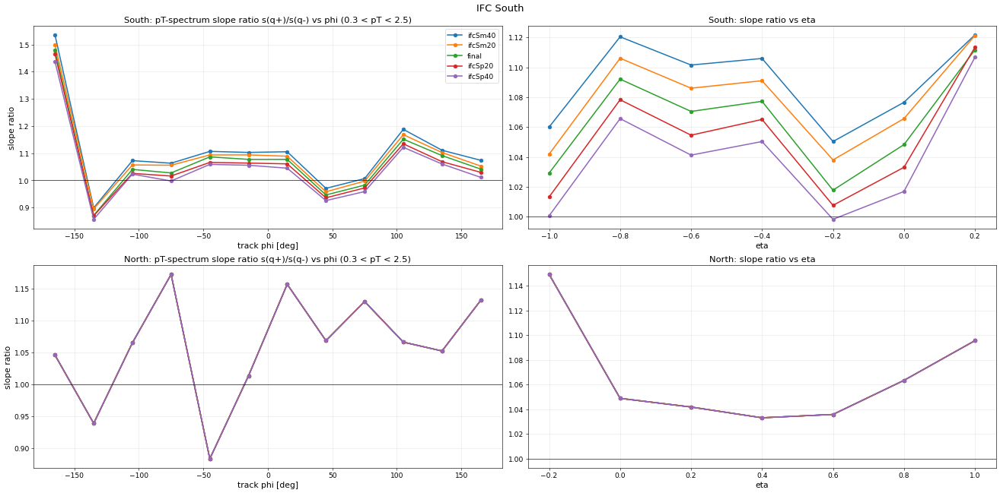

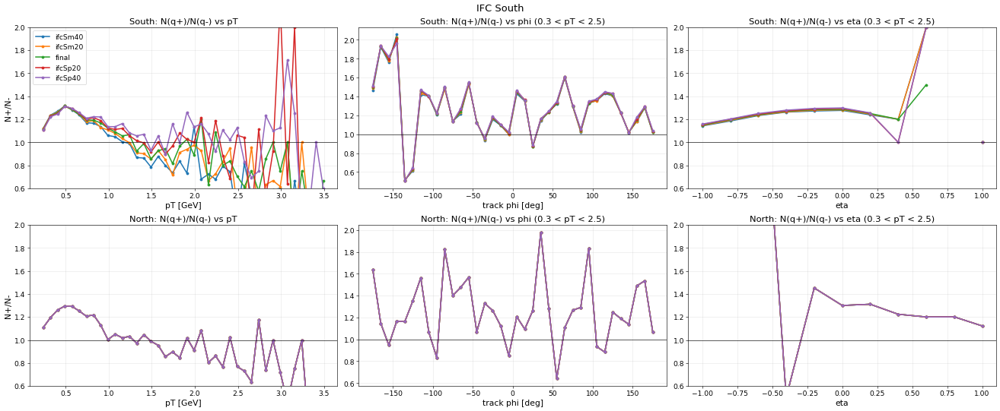

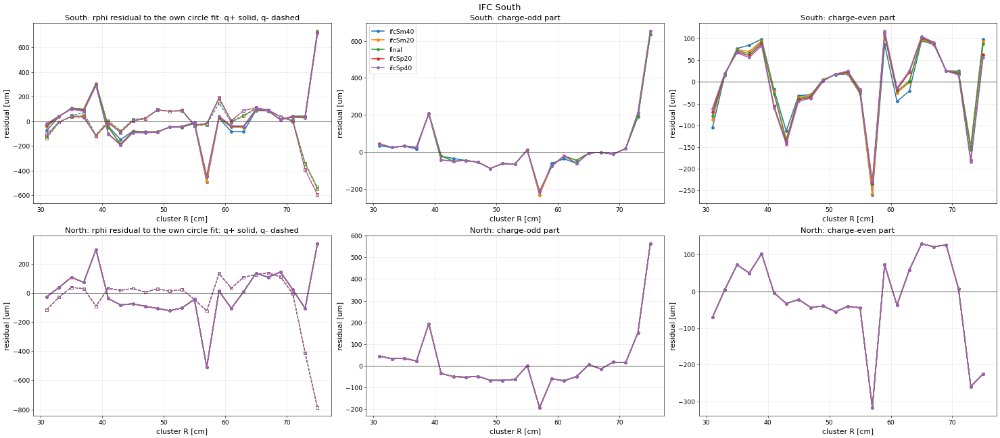

In [13]:
G = ta.GROUPS['IFC South']
show(ta.fig_dca_big(G, 'IFC South'), ta.fig_slope(G, 'IFC South'), ta.fig_yield_ratio([t for t in G if t != 'static'], 'IFC South'), ta.fig_resid(G, 'IFC South'))

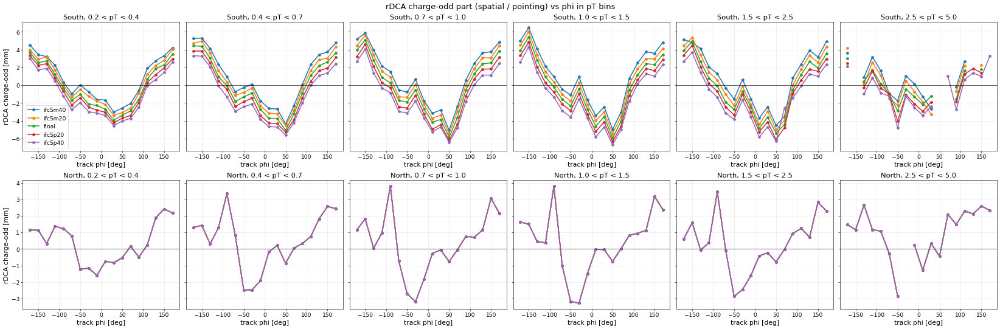

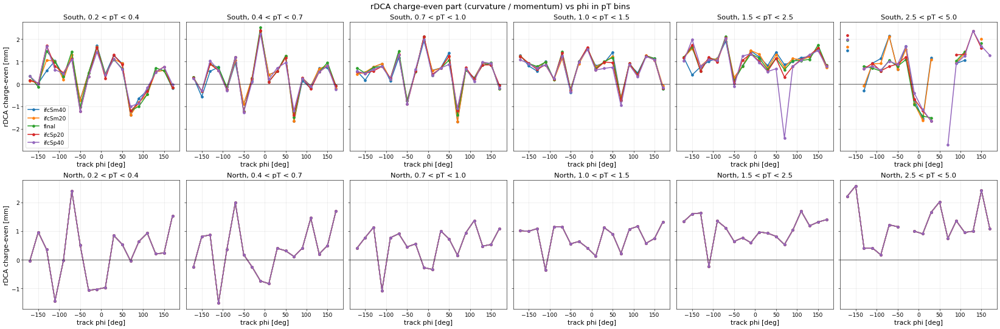

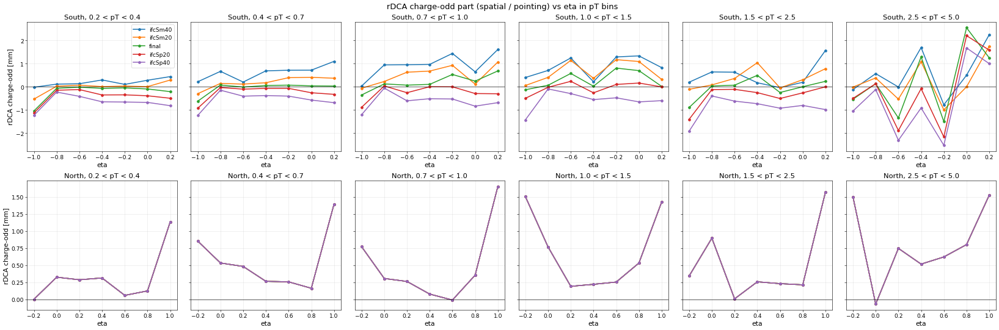

In [14]:
G = [t for t in ta.GROUPS['IFC South'] if t != 'static']
show(ta.fig_dca_ptbins(G, 'odd', 'phi'), ta.fig_dca_ptbins(G, 'even', 'phi'), ta.fig_dca_ptbins(G, 'odd', 'eta'))

### IFC North

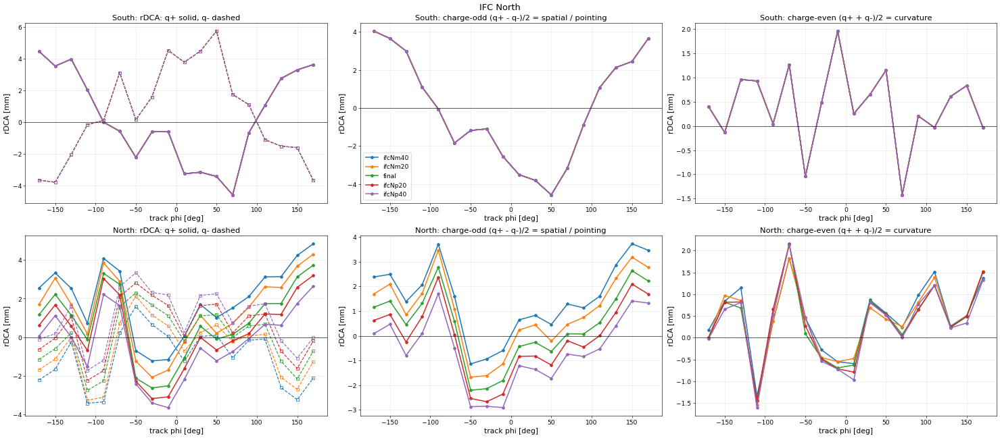

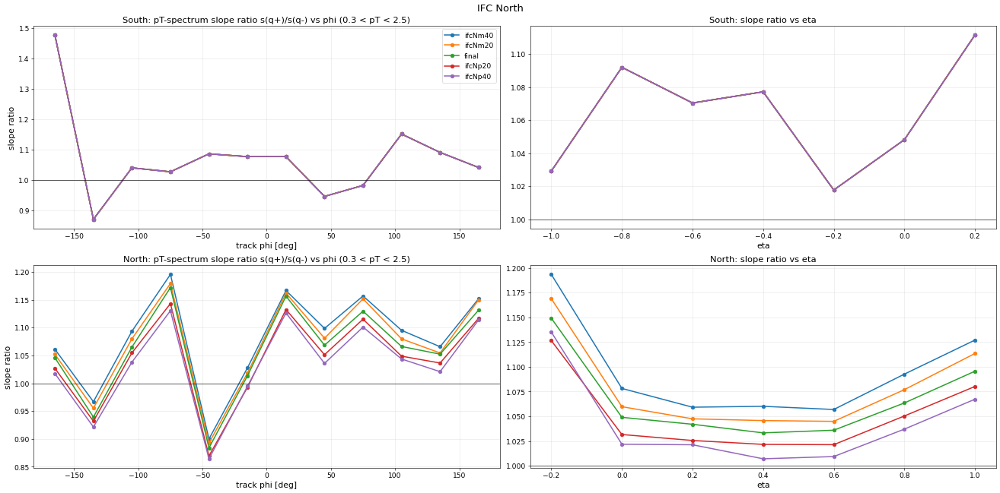

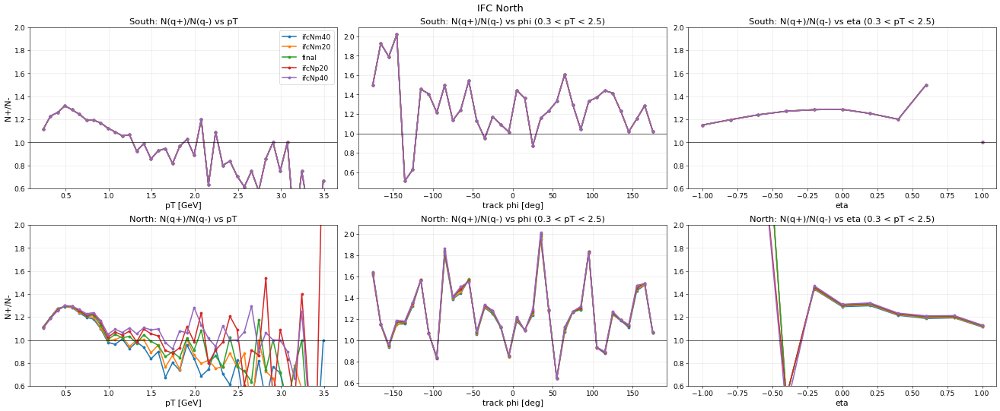

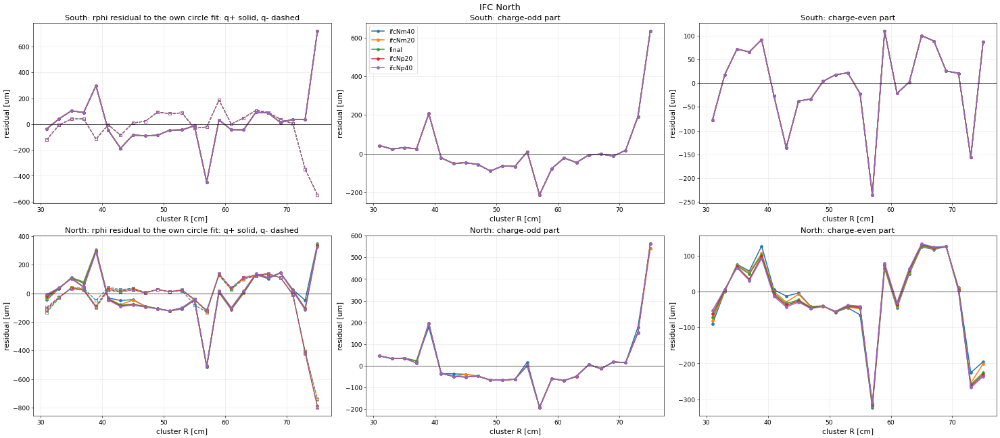

In [15]:
G = ta.GROUPS['IFC North']
show(ta.fig_dca_big(G, 'IFC North'), ta.fig_slope(G, 'IFC North'), ta.fig_yield_ratio([t for t in G if t != 'static'], 'IFC North'), ta.fig_resid(G, 'IFC North'))

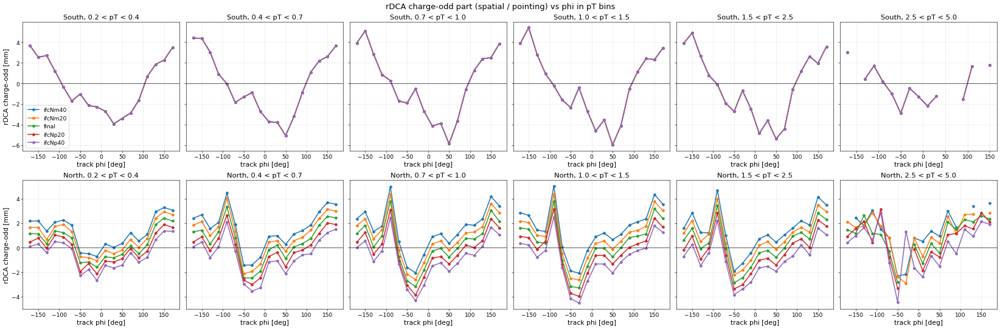

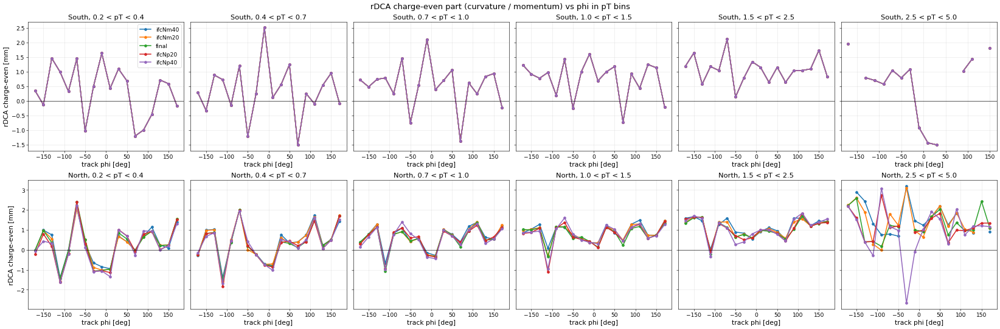

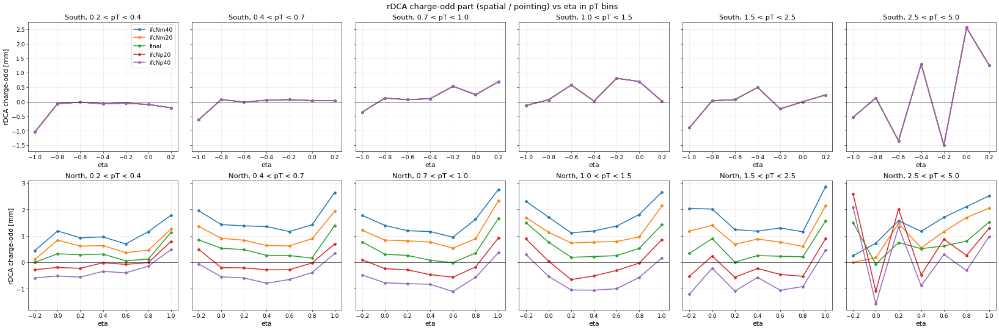

In [16]:
G = [t for t in ta.GROUPS['IFC North'] if t != 'static']
show(ta.fig_dca_ptbins(G, 'odd', 'phi'), ta.fig_dca_ptbins(G, 'even', 'phi'), ta.fig_dca_ptbins(G, 'odd', 'eta'))

### OFC

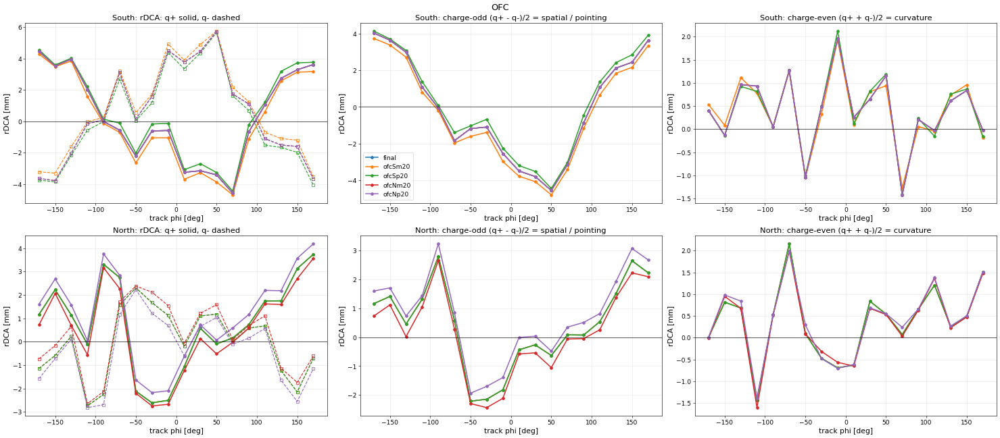

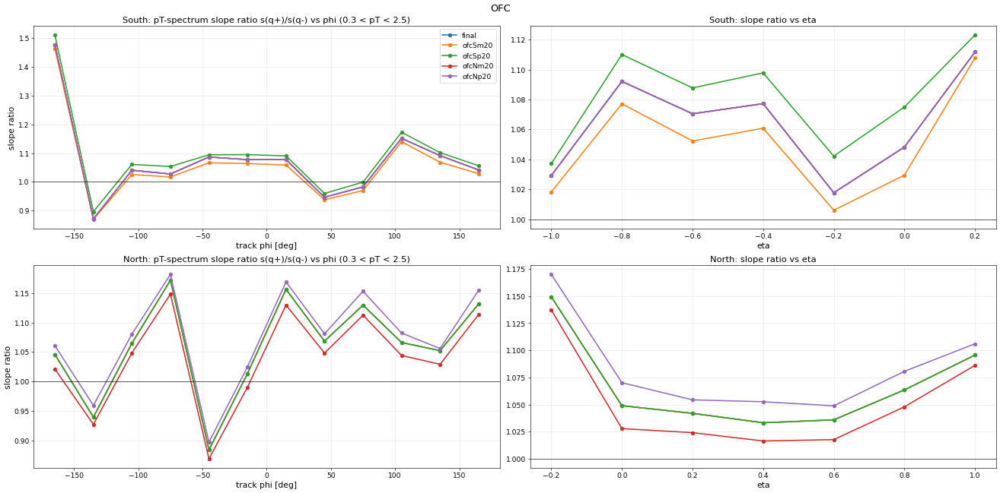

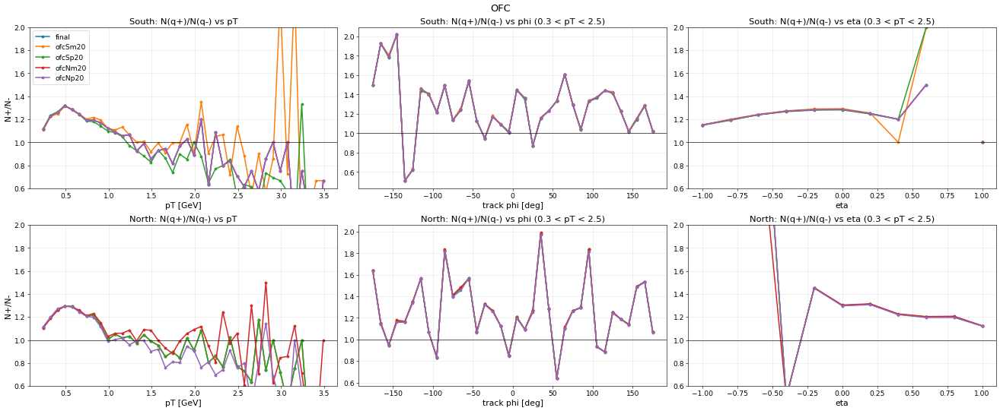

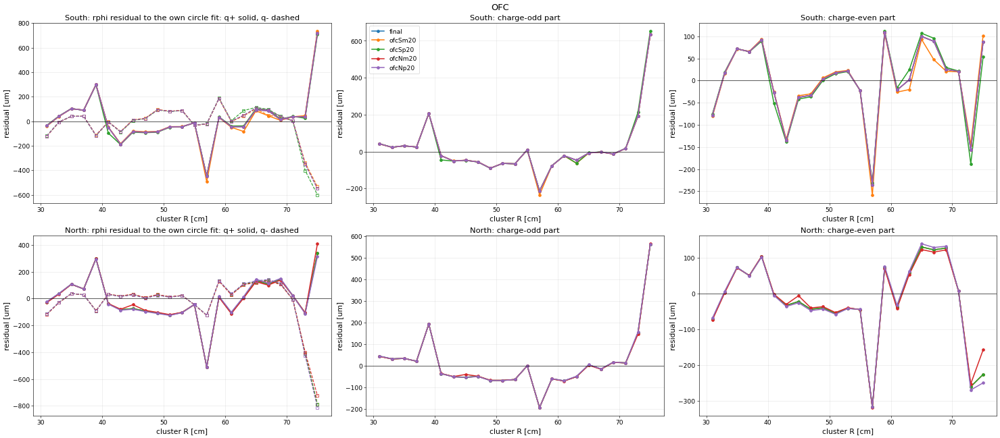

In [17]:
G = ta.GROUPS['OFC']
show(ta.fig_dca_big(G, 'OFC'), ta.fig_slope(G, 'OFC'), ta.fig_yield_ratio([t for t in G if t != 'static'], 'OFC'), ta.fig_resid(G, 'OFC'))

### frames

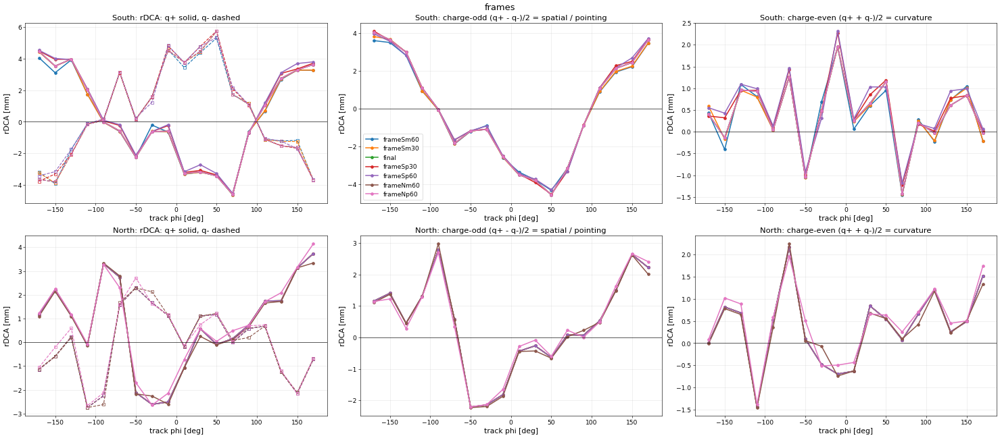

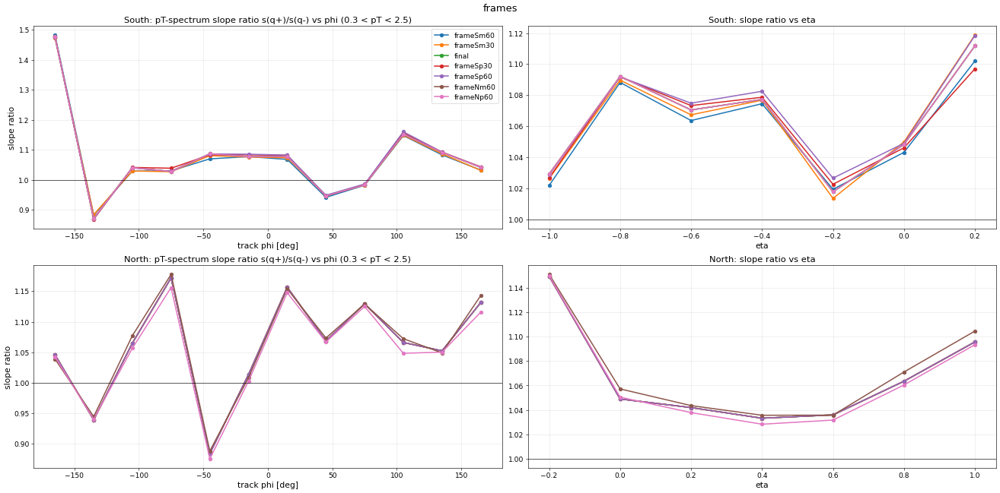

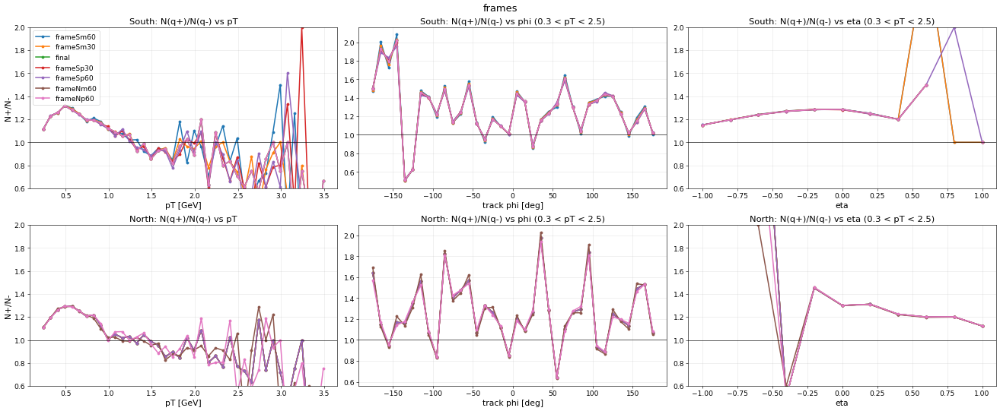

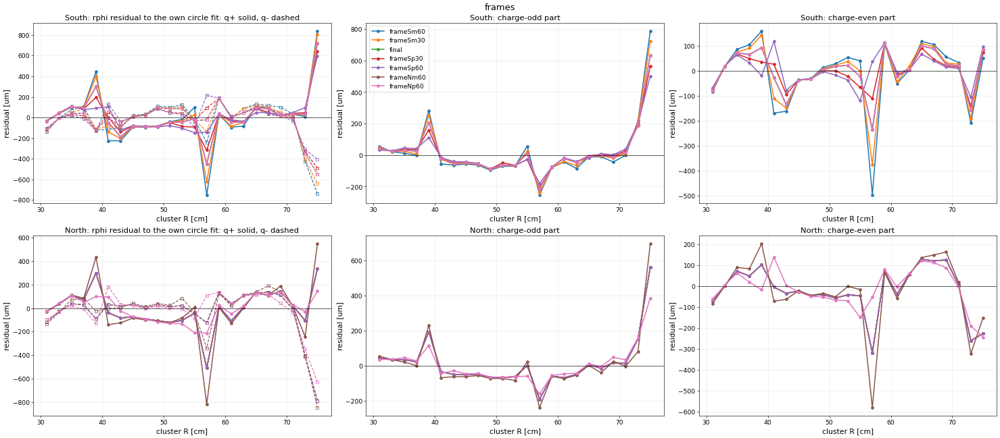

In [18]:
G = ta.GROUPS['frames']
show(ta.fig_dca_big(G, 'frames'), ta.fig_slope(G, 'frames'), ta.fig_yield_ratio([t for t in G if t != 'static'], 'frames'), ta.fig_resid(G, 'frames'))

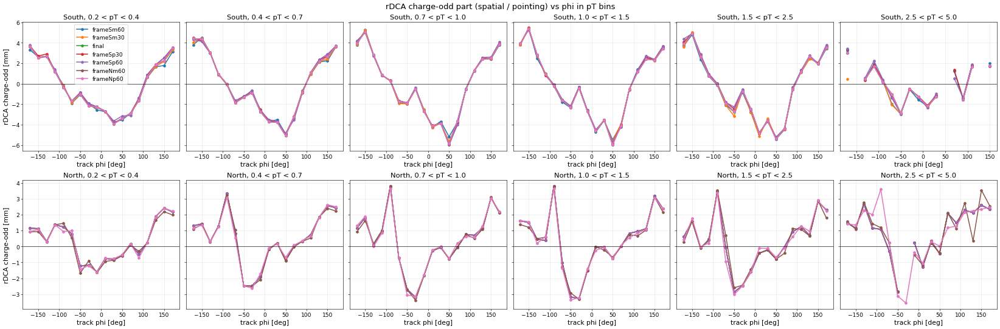

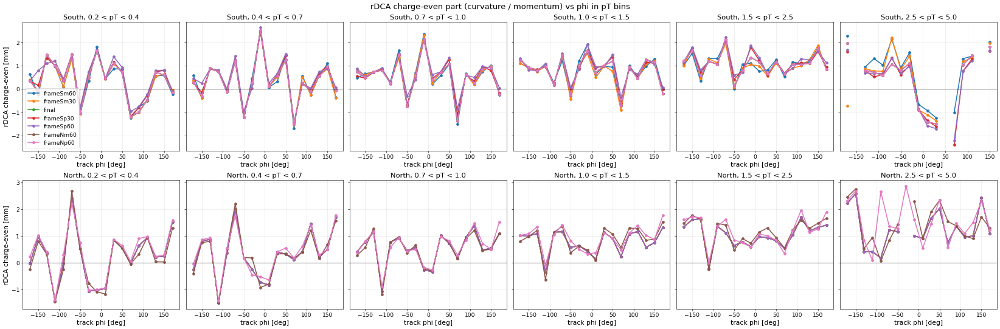

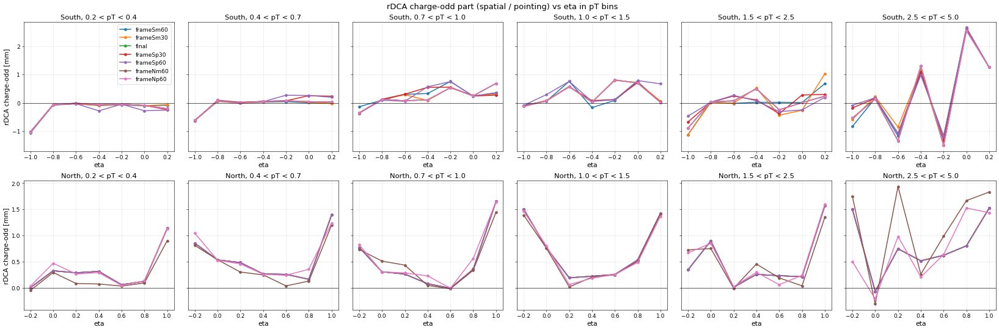

In [19]:
G = [t for t in ta.GROUPS['frames'] if t != 'static']
show(ta.fig_dca_ptbins(G, 'odd', 'phi'), ta.fig_dca_ptbins(G, 'even', 'phi'), ta.fig_dca_ptbins(G, 'odd', 'eta'))

### magnet / B / gas

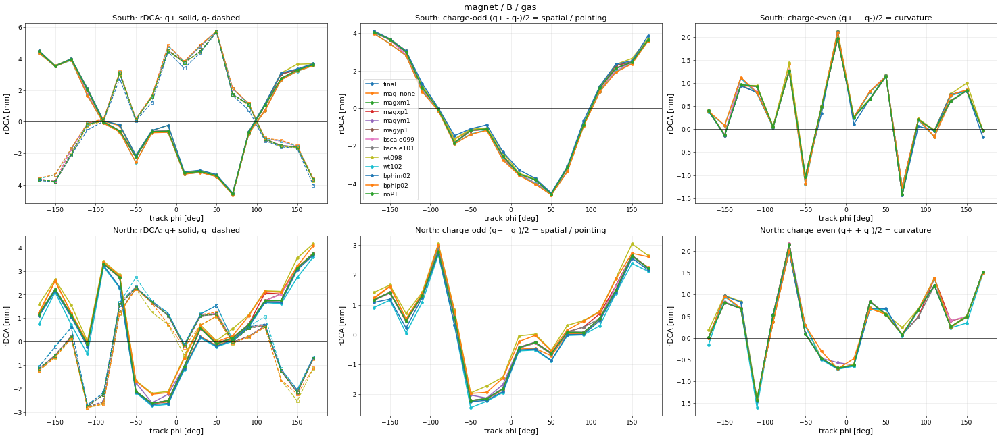

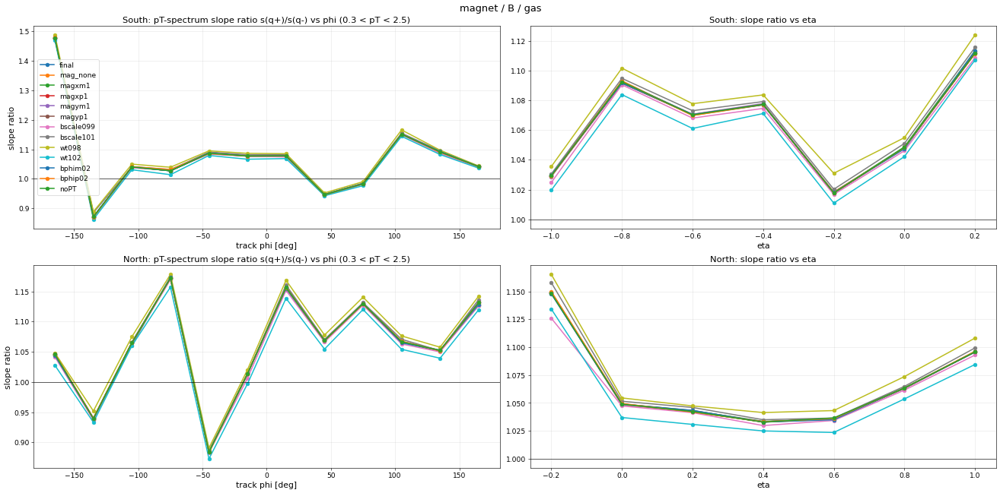

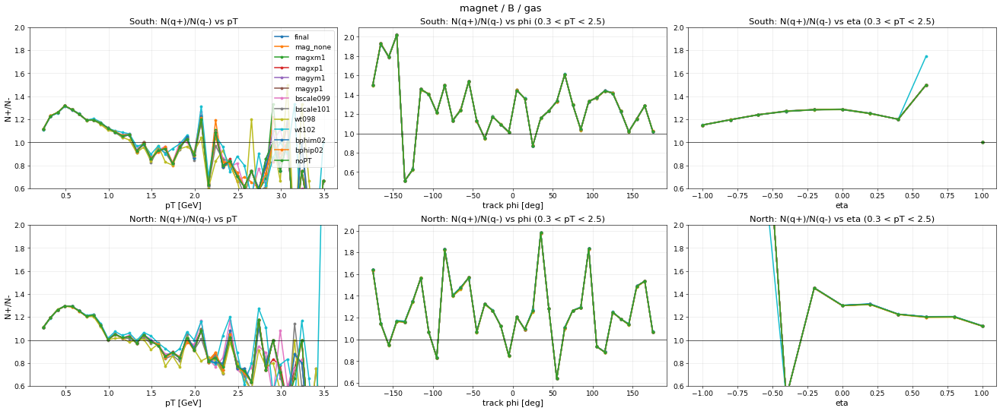

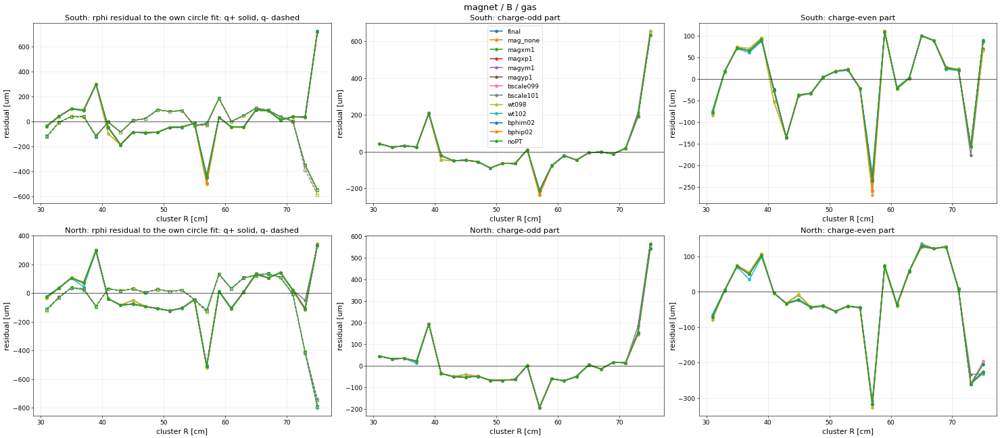

In [20]:
G = ta.GROUPS['magnet / B / gas']
show(ta.fig_dca_big(G, 'magnet / B / gas'), ta.fig_slope(G, 'magnet / B / gas'), ta.fig_yield_ratio([t for t in G if t != 'static'], 'magnet / B / gas'), ta.fig_resid(G, 'magnet / B / gas'))

## 4. Responses: observables vs the knob value

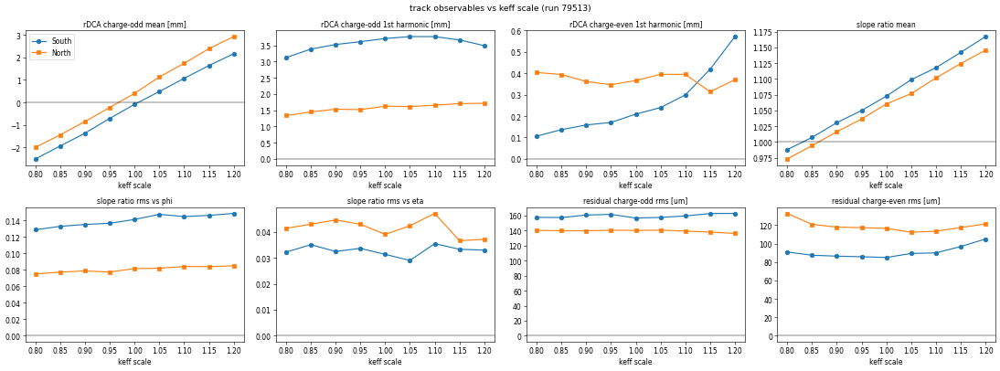

In [21]:
show(ta.fig_scan('keff scale'))

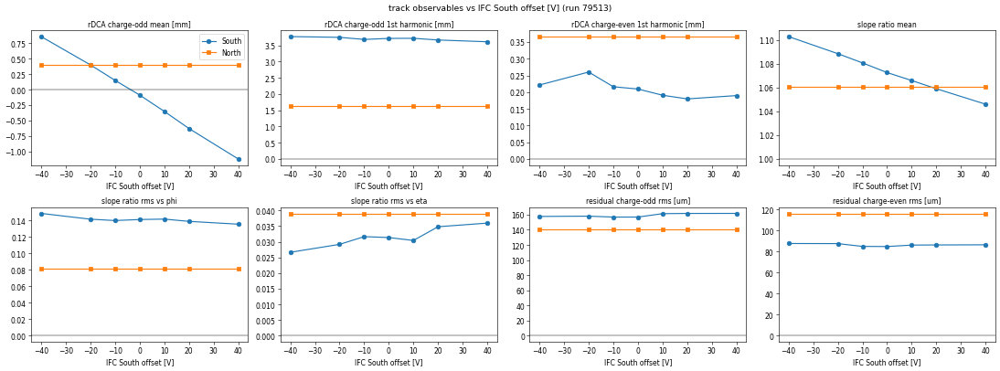

In [22]:
show(ta.fig_scan('IFC South offset [V]'))

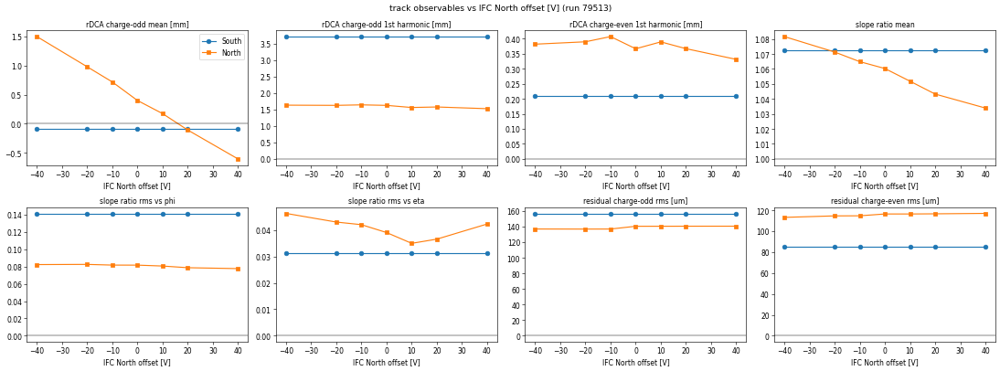

In [23]:
show(ta.fig_scan('IFC North offset [V]'))

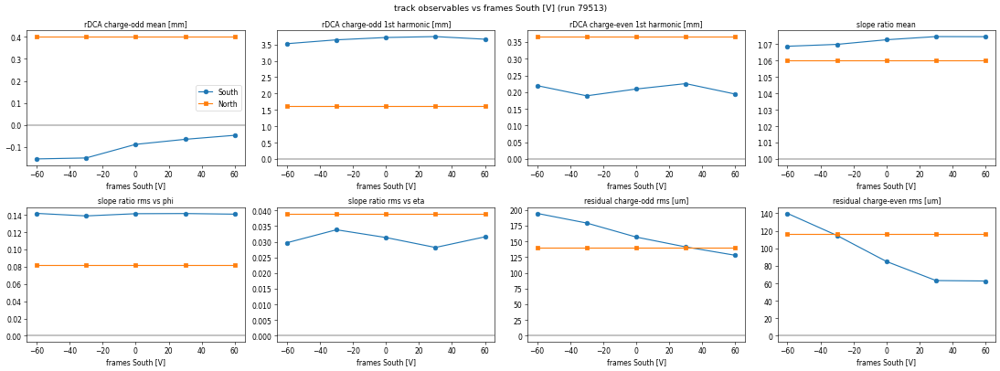

In [24]:
show(ta.fig_scan('frames South [V]'))

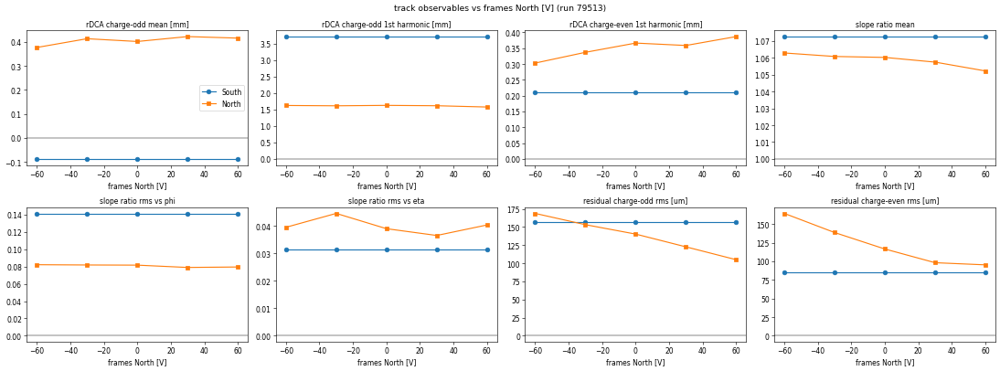

In [25]:
show(ta.fig_scan('frames North [V]'))

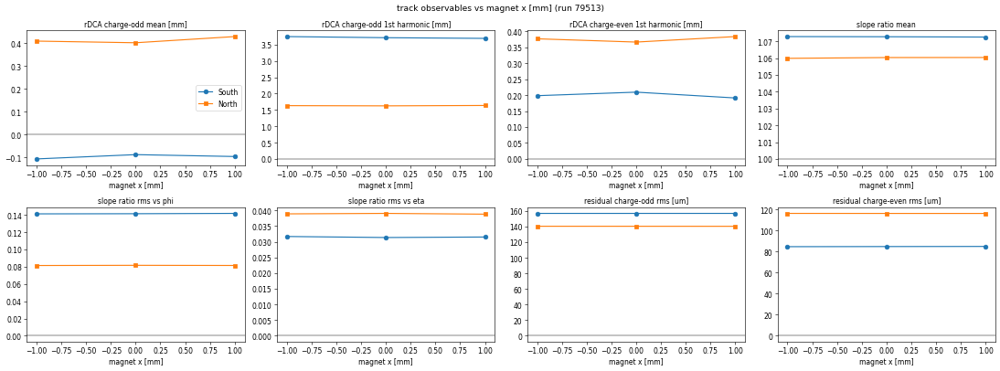

In [26]:
show(ta.fig_scan('magnet x [mm]'))

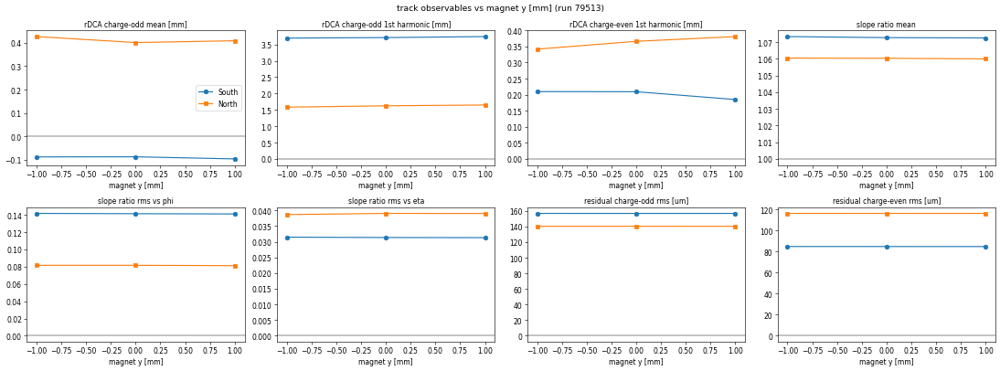

In [27]:
show(ta.fig_scan('magnet y [mm]'))